# Single- versus two-group MCWF dynamics

Run the same homogeneous $N=20$ MCWF model in a single-group representation, Ni=(20,), and an explicitly split representation, Ni=(10, 10). Both groups in the split model have unit coupling. The notebook compares additive full-system J and S observables and full-system squeezing, which should reproduce the single-group dynamics.

## Imports

In [1]:
from pathlib import Path
import sys

import numpy as np

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import (
    plot_bloch_angles,
    plot_spin_components,
    plot_squeezing,
)
from common.utils.moments import norm_spin_components_from_spin_components
from common.utils.parameters import (
    mcwf_dt_from_scales,
    omega_c,
    scaled_N_Gamma,
)
from common.utils.phases import default_three_phase_protocol
from parser.mcwf import MCWFSolverParameters
from parser.moments import MomentSeries, SimulationMetadata
from post_analysis import (
    build_dressed_basis_transformation,
    compute_gell_mann_rotation,
    compute_j_moments,
    compute_mean_generator_moments,
    compute_s_moments,
    compute_squeezing,
    rotate_generator_moments,
)
from solvers.mcwf.ensamble_sim import run_trajectory_ensemble

%reload_ext autoreload
%autoreload 2

/Users/ashar/.pyenv/versions/cavity-OAT_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Shared parameters

The physical scales and three-phase protocol follow main.ipynb. The same truncated binomial total-$N_J$ window and child trajectory seeds are used in both representations.

In [2]:
N = 20
Gamma = 1.0
dN = 2
ntraj = 100
num_snapshots = 100
seed = 1234
n_processes = -1

Omega_factor = 0.1
delta_factor = 0.02
durations = (10.0, 10.0, 10.0)

Omega0 = scaled_N_Gamma(Omega_factor, N, Gamma)
delta0 = scaled_N_Gamma(delta_factor, N, Gamma)
dt = mcwf_dt_from_scales(Omega0, delta0, N, Gamma)
phase_protocol = default_three_phase_protocol(
    durations=durations,
    delta0=delta0,
    Omega0=Omega0,
)

case_parameters = {
    "single group": {
        "Ni": (N,),
        "omega_i": (),
    },
    "two groups": {
        "Ni": (N // 2, N // 2),
        "omega_i": (1.0,),
    },
}

print(f"Omega0 = {Omega0:g}")
print(f"delta0 = {delta0:g}")
print(f"dt = {dt:g}")
print(
    "minimum-sector Omega0/Omega_c = "
    f"{Omega0 / omega_c(N // 2 - dN, Gamma):.3f}"
)

Omega0 = 2
delta0 = 0.4
dt = 0.005
minimum-sector Omega0/Omega_c = 0.500


## MCWF simulations and shared post-analysis

Each solver returns trajectory-resolved generator moments. Average complete trajectories, compute J and S in the lab frame, rotate the averaged moments into the dressed frame, and request both group-resolved and full-system squeezing.

In [3]:
moments_by_case = {}

for case_label, values in case_parameters.items():
    metadata = SimulationMetadata(
        Ni=values["Ni"],
        omega_i=values["omega_i"],
        Gamma=Gamma,
        phase_protocol=phase_protocol,
    )
    moments = MomentSeries(
        num_snapshots=num_snapshots,
        metadata=metadata,
    )
    parameters = MCWFSolverParameters(
        Ni=metadata.Ni,
        omega_i=metadata.omega_groups,
        Gamma=metadata.Gamma,
        phase_protocol=metadata.phase_protocol,
        dN=dN,
        sector_distribution="binomial",
        dt=dt,
        shifted_jump_operator=True,
    )

    print(
        f"Running {case_label}: Ni={metadata.Ni}, "
        f"couplings={metadata.omega_groups}"
    )
    ensemble = run_trajectory_ensemble(
        parameters,
        t_eval=moments.t,
        seed=seed,
        ntraj=ntraj,
        n_processes=n_processes,
        verbose=True,
    )

    moments.generator_moments = ensemble.moments
    moments.mean_generator_moments = compute_mean_generator_moments(
        moments.generator_moments
    )
    moments.J = compute_j_moments(
        moments.mean_generator_moments,
        metadata=moments.metadata,
    )
    moments.S = compute_s_moments(
        moments.mean_generator_moments,
        moments.J,
    )

    transformation = build_dressed_basis_transformation(moments.J, moments.S)
    rotation = compute_gell_mann_rotation(transformation)
    mean_dressed_generator_moments = rotate_generator_moments(
        moments.mean_generator_moments,
        rotation,
    )
    moments.squeezing = compute_squeezing(
        mean_dressed_generator_moments,
        moments.J,
        metadata=moments.metadata,
        include_full_system=True,
    )

    moments_by_case[case_label] = moments
    del ensemble


Running single group: Ni=(20,), couplings=(1.0,)
Precompute: 0.02 seconds.
Pool startup: 10 processes in 0.06 seconds.


simulate trajectories: 100%|██████████| 100/100 [00:04<00:00, 21.37it/s]


Simulation step summary (avg per trajectory): total steps=6046.17, steps without precompute=106.15
Running two groups: Ni=(10, 10), couplings=(1.0, 1.0)
Precompute: 0.27 seconds.
Pool startup: 10 processes in 6.30 seconds.


simulate trajectories: 100%|██████████| 100/100 [00:47<00:00,  2.11it/s]

Simulation step summary (avg per trajectory): total steps=6046.17, steps without precompute=106.15


## J angles

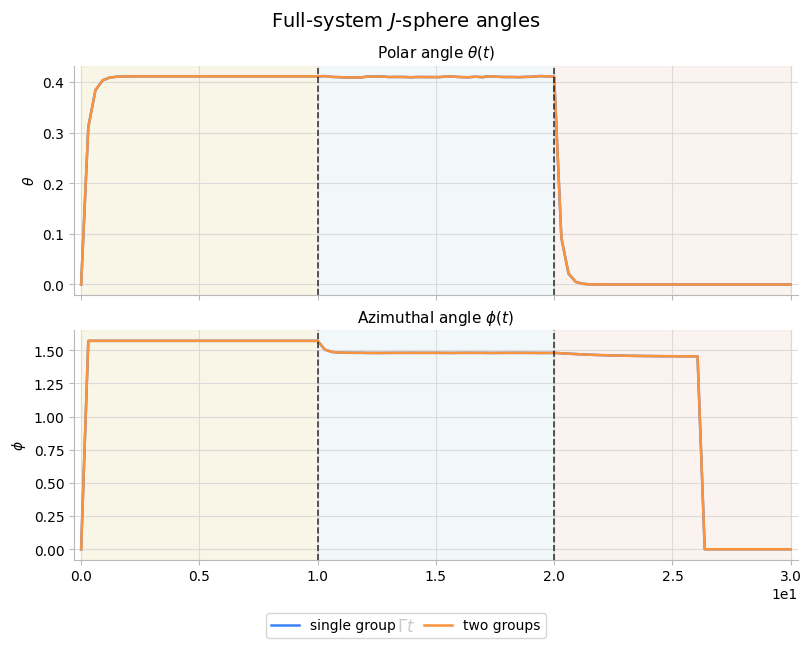

In [4]:
j_angle_fig, j_angle_axes = plot_bloch_angles(
    moments_by_case["single group"].J.t,
    moments_by_case["single group"].J.theta,
    moments_by_case["single group"].J.phi,
    labels=("single group",),
    colour_family_index=0,
    shade_index=2,
    linestyle="-",
    phase_protocol=phase_protocol,
    title=r"Full-system $J$-sphere angles",
)

j_angle_fig, j_angle_axes = plot_bloch_angles(
    moments_by_case["two groups"].J.t,
    moments_by_case["two groups"].J.aggregated.theta,
    moments_by_case["two groups"].J.aggregated.phi,
    labels=("two groups",),
    colour_family_index=1,
    shade_index=2,
    linestyle="-",
    axes=j_angle_axes,
    phase_protocol=phase_protocol,
    title=r"Full-system $J$-sphere angles",
)

## J components

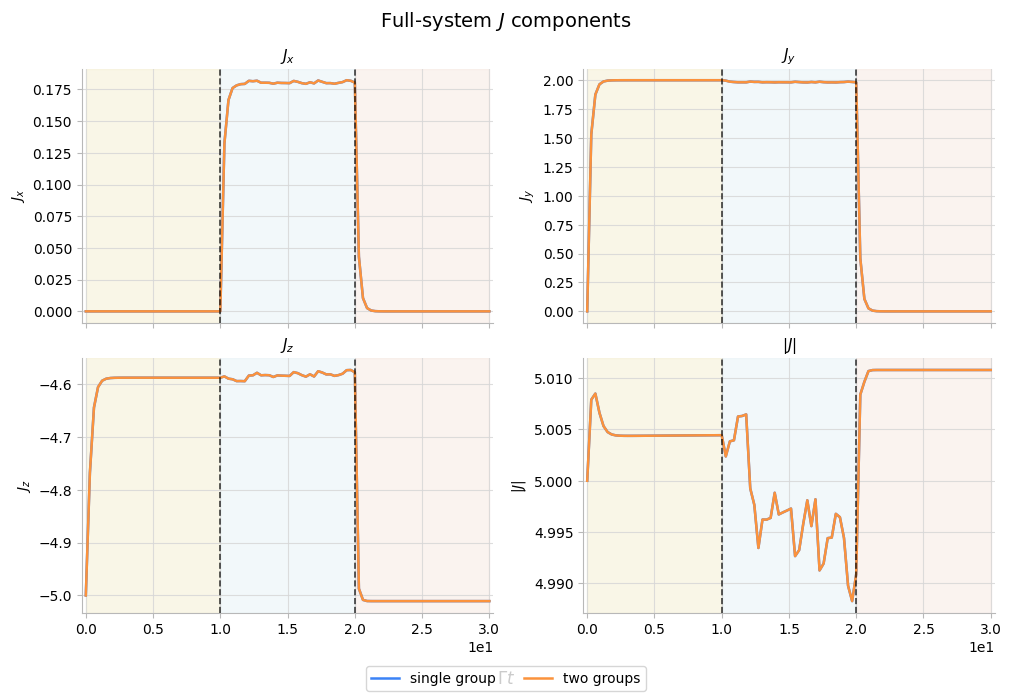

In [5]:
j_component_fig, j_component_axes = plot_spin_components(
    moments_by_case["single group"].J.t,
    moments_by_case["single group"].J.x,
    moments_by_case["single group"].J.y,
    moments_by_case["single group"].J.z,
    moments_by_case["single group"].J.length,
    labels=("single group",),
    colour_family_index=0,
    shade_index=2,
    linestyle="-",
    phase_protocol=phase_protocol,
    title=r"Full-system $J$ components",
    spin_symbol="J",
)

j_component_fig, j_component_axes = plot_spin_components(
    moments_by_case["two groups"].J.t,
    moments_by_case["two groups"].J.aggregated.x,
    moments_by_case["two groups"].J.aggregated.y,
    moments_by_case["two groups"].J.aggregated.z,
    moments_by_case["two groups"].J.aggregated.length,
    labels=("two groups",),
    colour_family_index=1,
    shade_index=2,
    linestyle="-",
    axes=j_component_axes,
    phase_protocol=phase_protocol,
    title=r"Full-system $J$ components",
    spin_symbol="J",
)

## S components

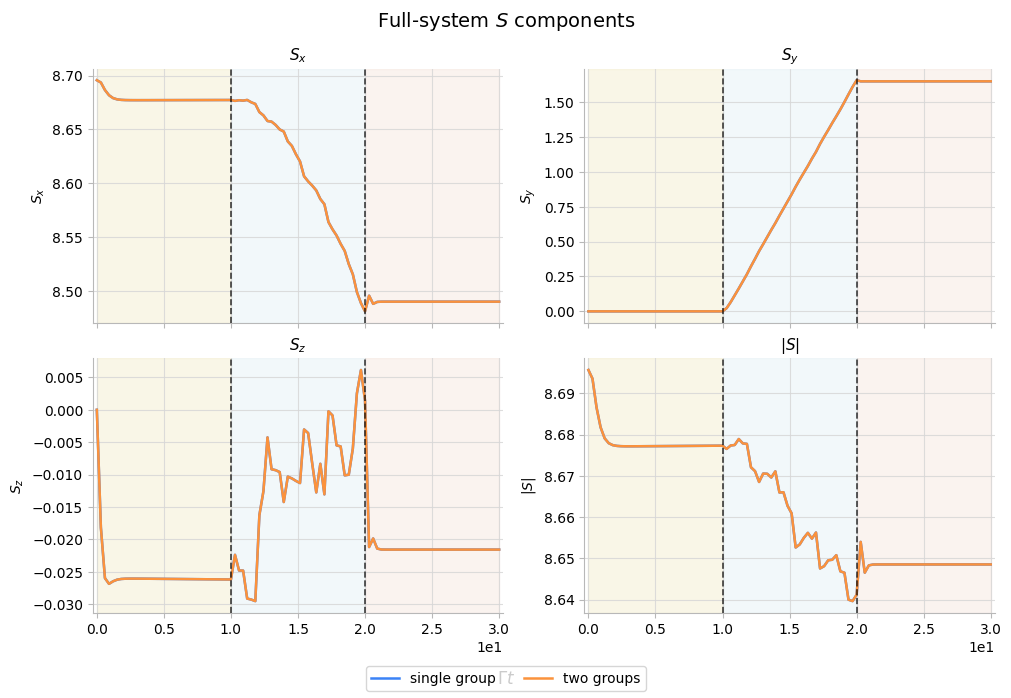

In [6]:
s_component_fig, s_component_axes = plot_spin_components(
    moments_by_case["single group"].S.t,
    moments_by_case["single group"].S.x,
    moments_by_case["single group"].S.y,
    moments_by_case["single group"].S.z,
    moments_by_case["single group"].S.length,
    labels=("single group",),
    colour_family_index=0,
    shade_index=2,
    linestyle="-",
    phase_protocol=phase_protocol,
    title=r"Full-system $S$ components",
    spin_symbol="S",
)

s_component_fig, s_component_axes = plot_spin_components(
    moments_by_case["two groups"].S.t,
    np.sum(np.stack(moments_by_case["two groups"].S.x), axis=0),
    np.sum(np.stack(moments_by_case["two groups"].S.y), axis=0),
    np.sum(np.stack(moments_by_case["two groups"].S.z), axis=0),
    norm_spin_components_from_spin_components(
        np.sum(np.stack(moments_by_case["two groups"].S.x), axis=0),
        np.sum(np.stack(moments_by_case["two groups"].S.y), axis=0),
        np.sum(np.stack(moments_by_case["two groups"].S.z), axis=0),
    )[0],
    labels=("two groups",),
    colour_family_index=1,
    shade_index=2,
    linestyle="-",
    axes=s_component_axes,
    phase_protocol=phase_protocol,
    title=r"Full-system $S$ components",
    spin_symbol="S",
)

## Full-system squeezing

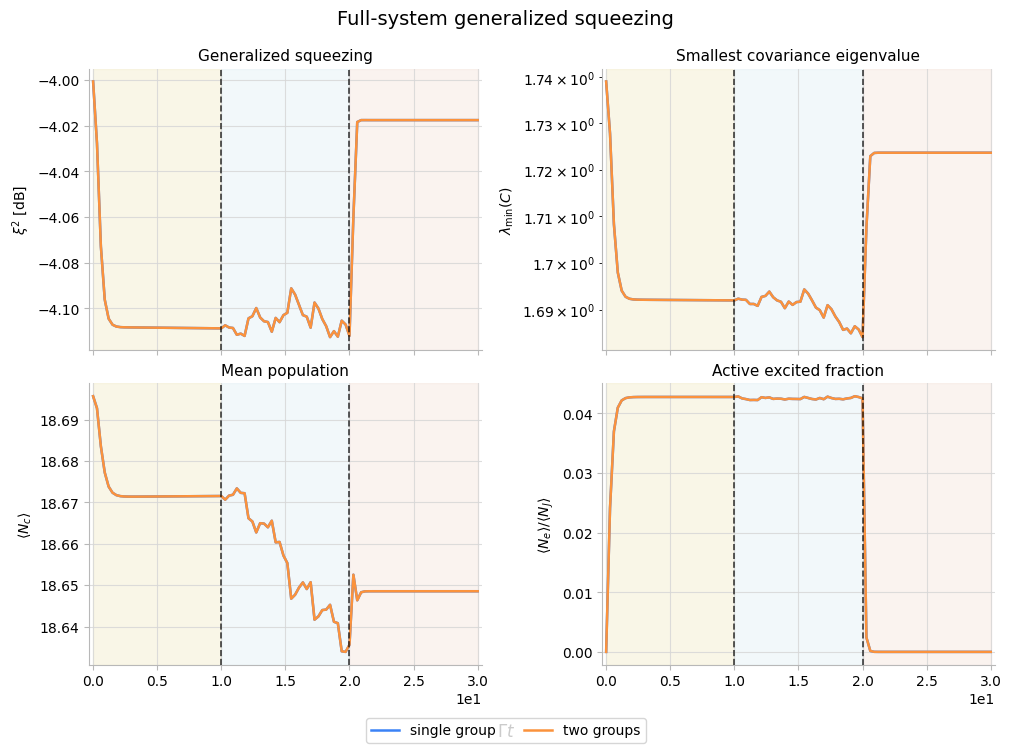

In [7]:
squeezing_fig, squeezing_axes = plot_squeezing(
    moments_by_case["single group"].squeezing.full_system.t,
    moments_by_case["single group"].squeezing.full_system.xi2,
    moments_by_case["single group"].squeezing.full_system.lambda_min,
    moments_by_case["single group"].squeezing.full_system.N_c,
    moments_by_case["single group"].squeezing.full_system.excited_fraction_active,
    labels=("single group",),
    colour_family_index=0,
    shade_index=2,
    linestyle="-",
    phase_protocol=phase_protocol,
    title="Full-system generalized squeezing",
)

squeezing_fig, squeezing_axes = plot_squeezing(
    moments_by_case["two groups"].squeezing.full_system.t,
    moments_by_case["two groups"].squeezing.full_system.xi2,
    moments_by_case["two groups"].squeezing.full_system.lambda_min,
    moments_by_case["two groups"].squeezing.full_system.N_c,
    moments_by_case["two groups"].squeezing.full_system.excited_fraction_active,
    labels=("two groups",),
    colour_family_index=1,
    shade_index=2,
    linestyle="-",
    axes=squeezing_axes,
    phase_protocol=phase_protocol,
    title="Full-system generalized squeezing",
)

## Maximum differences

Report numerical discrepancies without imposing a brittle assertion on stochastic trajectories. The same seeds should make the two representations closely track each other, but floating-point differences can eventually alter individual jump histories.

In [8]:
def maximum_finite_difference(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    valid = np.isfinite(left) & np.isfinite(right)
    if not np.any(valid):
        return np.nan
    return float(np.max(np.abs(left[valid] - right[valid])))


single_j = moments_by_case["single group"].J.aggregated
two_group_j = moments_by_case["two groups"].J.aggregated
single_s = {
    component: getattr(moments_by_case["single group"].S, component)[0]
    for component in ("x", "y", "z", "length")
}
two_group_s = {
    component: np.sum(
        np.stack(getattr(moments_by_case["two groups"].S, component)),
        axis=0,
    )
    for component in ("x", "y", "z")
}
two_group_s["length"] = norm_spin_components_from_spin_components(
    two_group_s["x"],
    two_group_s["y"],
    two_group_s["z"],
)[0]
single_squeezing = moments_by_case["single group"].squeezing.full_system
two_group_squeezing = moments_by_case["two groups"].squeezing.full_system

comparison_errors = {
    "Jx": maximum_finite_difference(single_j.x, two_group_j.x),
    "Jy": maximum_finite_difference(single_j.y, two_group_j.y),
    "Jz": maximum_finite_difference(single_j.z, two_group_j.z),
    "J length": maximum_finite_difference(
        single_j.length, two_group_j.length
    ),
    "J theta": maximum_finite_difference(single_j.theta, two_group_j.theta),
    "J phi (wrapped)": maximum_finite_difference(
        np.angle(np.exp(1j * (single_j.phi - two_group_j.phi))),
        np.zeros_like(single_j.phi),
    ),
    "Sx": maximum_finite_difference(single_s["x"], two_group_s["x"]),
    "Sy": maximum_finite_difference(single_s["y"], two_group_s["y"]),
    "Sz": maximum_finite_difference(single_s["z"], two_group_s["z"]),
    "S length": maximum_finite_difference(
        single_s["length"], two_group_s["length"]
    ),
    "xi2": maximum_finite_difference(
        single_squeezing.xi2, two_group_squeezing.xi2
    ),
    "lambda_min": maximum_finite_difference(
        single_squeezing.lambda_min, two_group_squeezing.lambda_min
    ),
    "N_c": maximum_finite_difference(
        single_squeezing.N_c, two_group_squeezing.N_c
    ),
}

comparison_errors

{'Jx': 1.2184697695261093e-14,
 'Jy': 3.7914116290949096e-14,
 'Jz': 2.7977620220553945e-13,
 'J length': 2.5490720645393594e-13,
 'J theta': 2.1073424255447017e-08,
 'J phi (wrapped)': 5.995204332975845e-15,
 'Sx': 1.474376176702208e-13,
 'Sy': 2.142730437526552e-13,
 'Sz': 5.11229947264269e-13,
 'S length': 1.4566126083082054e-13,
 'xi2': 3.4638958368304884e-14,
 'lambda_min': 1.2789769243681803e-13,
 'N_c': 1.4566126083082054e-13}